# State vectors and measurements



We can make use of the class Statevector to define a state vector in the computational base, display it and check if it is a valid state vector.

In [31]:
from qiskit.quantum_info import Statevector

state_0 = [1, 0]
state_1 = [0, 1]

ket0 = Statevector(state_0)
ket1 = Statevector(state_1)

display(ket0.draw('text'), ket0.draw('latex'))
display(ket1.draw('text'), ket1.draw('latex'))

#verify that it is a valid state vector
print(ket1.is_valid())  # True

[1.+0.j,0.+0.j]

<IPython.core.display.Latex object>

[0.+0.j,1.+0.j]

<IPython.core.display.Latex object>

True


Try with a non-normalized state vector

In [32]:

## define vector
u = Statevector([1,1])
display(u.draw('latex'))

## check is valid
print(u.is_valid())     # False


<IPython.core.display.Latex object>

False


Let's define a valid mixed state vector and do some measurements.
Measurements are probabilistic, so runnig the same cell give different resulst:

In [79]:
ket_mix = Statevector([1/sqrt(2),1/sqrt(2)])
ket_mix.is_valid()
display(ket_mix.draw('latex'))

# measure: returns the result of measurement and the remaining state vector
ket_measured = ket_mix.measure()
print(type(ket_measured),'\n')
print(f'measurement output = {ket_measured[0]}')
print(f'remaining statevector = {ket_measured[1].draw("text")}')
#display(ket_measured.draw('latex'))

<IPython.core.display.Latex object>

<class 'tuple'> 

measurement output = 0
remaining statevector = [1.+0.j,0.+0.j]


In [80]:
## Now let's see what happens when we measure again the same statevector
ket_mix = ket_measured[1]

ket_measured = ket_mix.measure()
print(type(ket_measured),'\n')
print(f'measurement output = {ket_measured[0]}')
print(f'remaining statevector = {ket_measured[1].draw("text")}')
#display(ket_measured.draw('latex'))


ket_mix = ket_measured[1]

ket_measured = ket_mix.measure()
print(type(ket_measured),'\n')
print(f'measurement output = {ket_measured[0]}')
print(f'remaining statevector = {ket_measured[1].draw("text")}')
#display(ket_measured.draw('latex'))


ket_mix = ket_measured[1]

ket_measured = ket_mix.measure()
print(type(ket_measured),'\n')
print(f'measurement output = {ket_measured[0]}')
print(f'remaining statevector = {ket_measured[1].draw("text")}')
#display(ket_measured.draw('latex'))


ket_mix = ket_measured[1]

ket_measured = ket_mix.measure()
print(type(ket_measured),'\n')
print(f'measurement output = {ket_measured[0]}')
print(f'remaining statevector = {ket_measured[1].draw("text")}')
#display(ket_measured.draw('latex'))


<class 'tuple'> 

measurement output = 0
remaining statevector = [1.+0.j,0.+0.j]
<class 'tuple'> 

measurement output = 0
remaining statevector = [1.+0.j,0.+0.j]
<class 'tuple'> 

measurement output = 0
remaining statevector = [1.+0.j,0.+0.j]
<class 'tuple'> 

measurement output = 0
remaining statevector = [1.+0.j,0.+0.j]


The wave function has collapsed after the first measurement.

Let's continue with a more graphical representation..

## initialize states
In our quantum circuits, our qubits always start out in the state . We can use the initialize() method to transform this into any state. We give initialize() the vector we want in the form of a list, and tell it which qubit(s) we want to initialize in this state:

In [81]:
from qiskit import QuantumCircuit, assemble, Aer
from qiskit.visualization import plot_histogram, plot_bloch_vector
from math import sqrt, pi

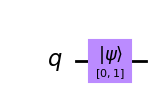

In [82]:
qc = QuantumCircuit(1)  # Create a quantum circuit with one qubit
initial_state = [0,1]   # Define initial_state as |1>, this is the column vector [0,1]
qc.initialize(initial_state, 0) # Apply initialisation operation to the 0th qubit
qc.draw()  # Let's view our circuit

use one of Qiskit’s simulators to view the resulting state of our qubit.  
To get the results from our circuit, we use run to execute our circuit, giving the circuit and the backend as arguments. We then use .result() to get the result of this:

In [36]:
sim = Aer.get_backend('aer_simulator')  # Tell Qiskit how to simulate our circuit
qc.save_statevector()   # Tell simulator to save statevector
result = sim.run(qc).result() # Do the simulation and return the result

from result, we can then get the final statevector using .get_statevector():

In [38]:
out_state = result.get_statevector()

## Three ways of visualizing the vector
print(out_state)
display(out_state.draw('text'))
display(out_state.draw('latex')) # Display the output state vector

Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


[0.+0.j,1.+0.j]

<IPython.core.display.Latex object>

Let’s now measure our qubit as we would in a real quantum computer and see the result:

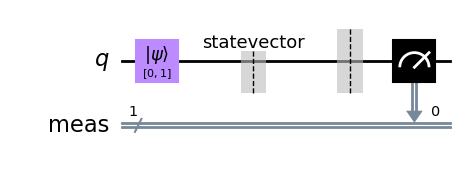

In [12]:
qc.measure_all()
qc.draw()

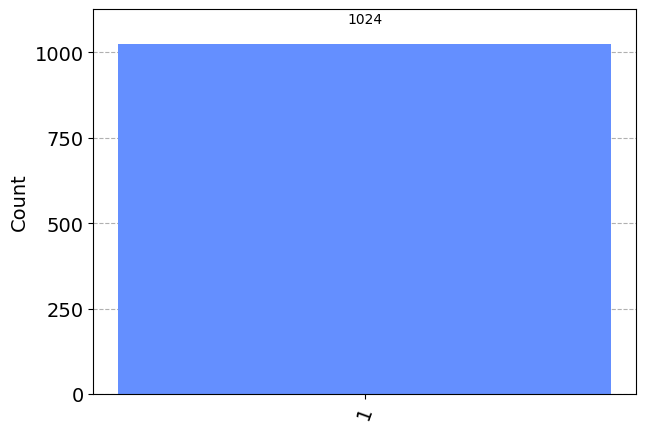

In [13]:
#qobj = assemble(qc)
result = sim.run(qc).result()
counts = result.get_counts()
plot_histogram(counts)

## Superposition

let’s instead put our qubit into a superposition and see what happens. 
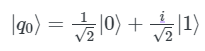

In [16]:
initial_state = [1/sqrt(2), 1j/sqrt(2)]  # Define state |q_0>

qc = QuantumCircuit(1) # Must redefine qc
qc.initialize(initial_state, 0) # Initialize the 0th qubit in the state `initial_state`
qc.save_statevector() # Save statevector
#qobj = assemble(qc)
state = sim.run(qc).result().get_statevector() # Execute the circuit
display(state.draw('latex'))           # Print the result
display(state.draw('text'))

<IPython.core.display.Latex object>

[0.70710678+0.j        ,0.        +0.70710678j]

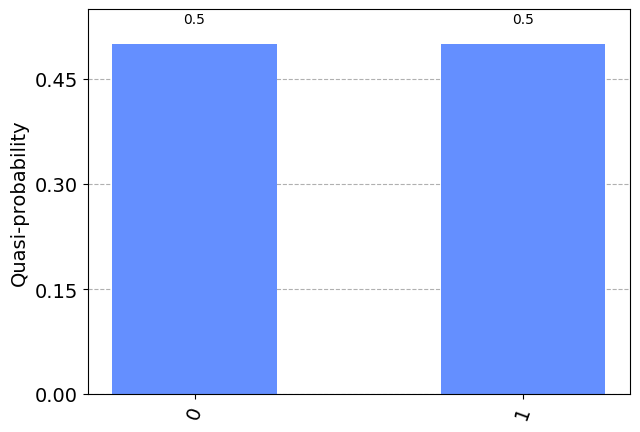

In [17]:
results = sim.run(qc).result().get_counts()
plot_histogram(results)

We can see we have 50% probability of measuring  compared to . To explain this, we need to talk about measurement.

## The Rule of Measurements
To find the probability of measuring a state $|\psi\rangle$ in the state $|x\rangle$ we do:
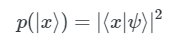
This is the Born rule.
It has some implications:  
1- State must be normalized  

 

In [19]:
# if not normalized, the initialization gives an error
vector = [1,1]
qc.initialize(vector, 0)


Traceback (most recent call last):
  Cell In[19], line 3
    qc.initialize(vector, 0)
  File /opt/conda/lib/python3.10/site-packages/qiskit/extensions/quantum_initializer/initializer.py:191 in initialize
    return self.append(Initialize(params, num_qubits), qubits)
  File /opt/conda/lib/python3.10/site-packages/qiskit/extensions/quantum_initializer/initializer.py:57 in __init__
    self._stateprep = StatePreparation(params, num_qubits)
  File /opt/conda/lib/python3.10/site-packages/qiskit/circuit/library/data_preparation/state_preparation.py:99 in __init__
    num_qubits = self._get_num_qubits(num_qubits, params)
  File /opt/conda/lib/python3.10/site-packages/qiskit/circuit/library/data_preparation/state_preparation.py:202 in _get_num_qubits
    raise QiskitError("Sum of amplitudes-squared does not equal one.")
QiskitError: 'Sum of amplitudes-squared does not equal one.'

Use %tb to get the full traceback.


2- We can project in any state x, not only in 0 or 1.  
3- Global phase do not matter  


4- The observer effect: wavefunction collapse. 
We know that the amplitudes contain information about the probability of us finding the qubit in a specific state, but once we have measured the qubit, we know with certainty what the state of the qubit is.  
This means the act of measuring changes the state of our qubits.

We sometimes refer to this as collapsing the state of the qubit. It is a potent effect, and so one that must be used wisely.

We can demonstrate this using Qiskit’s statevector simulator:

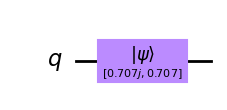

In [55]:
qc = QuantumCircuit(1) # We are redefining qc
initial_state = [0.+1.j/sqrt(2),1/sqrt(2)+0.j]
qc.initialize(initial_state, 0)
qc.draw()

In [34]:
#We can verify this using the simulator: 

qc.save_statevector()
result = sim.run(qc).result()
state = result.get_statevector()
print("Qubit State = " + str(state))

Qubit State = Statevector([0.        +0.70710678j, 0.70710678+0.j        ],
            dims=(2,))


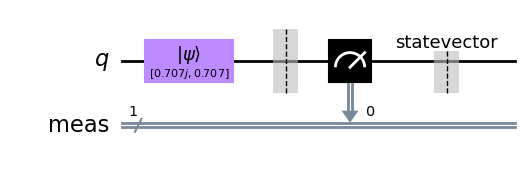

In [56]:
#After having created the circuit, Let’s now measure this qubit:
qc.measure_all()
qc.save_statevector()
qc.draw()

When we simulate this entire circuit, we can see that one of the amplitudes is always 0:  
(You can re-run this cell a few times to reinitialize the qubit and measure it again.)

In [57]:
state = sim.run(qc).result().get_statevector()
print("State of Measured Qubit = " + str(state))

State of Measured Qubit = Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


## The Block Sphere

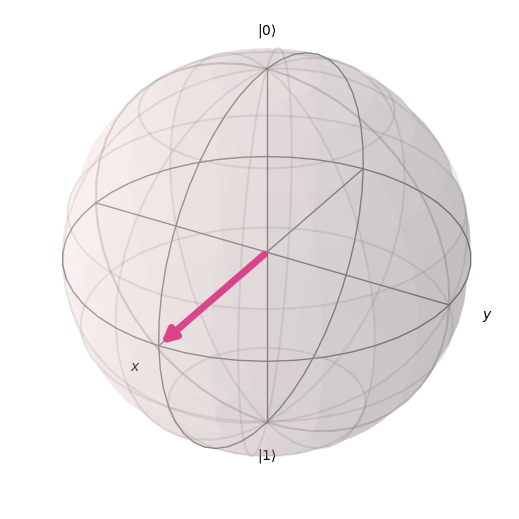

In [59]:
from qiskit_textbook.widgets import plot_bloch_vector_spherical
coords = [pi/2,0,1] # [Theta, Phi, Radius]
plot_bloch_vector_spherical(coords) # Bloch Vector with spherical coordinates

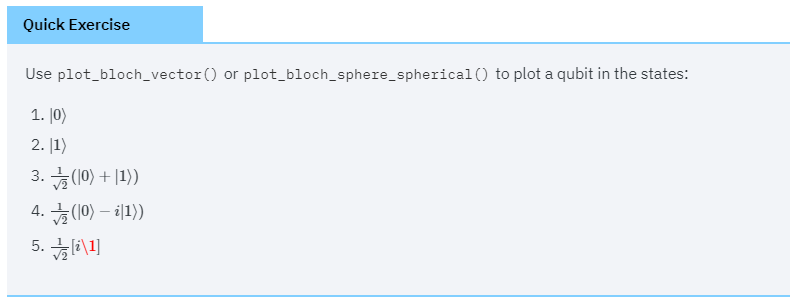

# Perform operations with Operators and Statevectors

In [83]:
from qiskit.quantum_info import Operator

## define unitary operations using the Operator class
X = Operator([ [0,1],[1,0] ])
Y = Operator([ [0,-1.j],[1.j,0] ])
Z = Operator([ [1,0],[0,-1] ])
H = Operator([ [1/sqrt(2),1/sqrt(2)],[1/sqrt(2),-1/sqrt(2)] ])
S = Operator([ [1,0],[0,1.j] ])
T = Operator([ [1,0],[0,(1+1.j)/sqrt(2)] ])

v = Statevector([1,0])

v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(Z)

v.draw('latex')

<IPython.core.display.Latex object>

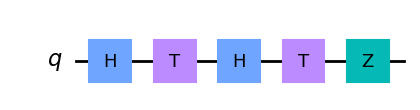

In [84]:
## Quantum circuits can be used to define composed unitary operation too
## this is using the quantum circuit class

from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.t(0)
circuit.z(0)

circuit.draw()

The operations are applied sequentially, starting on the left and ending on the right in the figure. Let us first initialize a starting quantum state vector and then evolve that state according to the sequence of operations.

In [85]:
ket0 = Statevector([1,0])
v = ket0.evolve(circuit)
v.draw('latex')

<IPython.core.display.Latex object>

Finally, let's simulate the result of running this experiment (i.e., preparing the state , applying the sequence of operations represented by the circuit, and measuring) 4000 times.

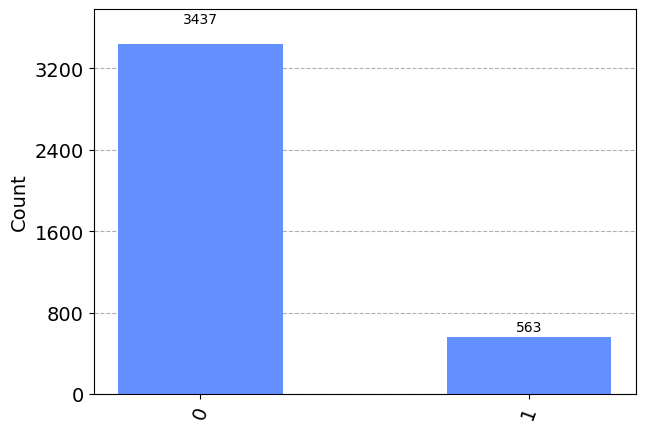

In [87]:
statistics = v.sample_counts(4000)
plot_histogram(statistics)